# 14-模仿学习与行为克隆


## 1. 本篇范围与课程主题

本篇依据《具身智能-模仿学习》的 **7 页 PPT** 整理。课件首页标题为《模仿学习（离线强化学习）与行为克隆》，依次介绍机器人示范、行为克隆、自动驾驶应用，以及先模仿学习、再强化学习的训练思路。

上一篇讨论了智能体如何利用奖励学习策略。这一篇引入另一种学习依据：**专家在某种情况下实际采取的动作**。机器人可以先学习这些示范，获得完成任务的初始能力。

**标题辨析：**模仿学习与离线强化学习并不等同。行为克隆是模仿学习的一种常用方法，可以使用事先采集的数据进行监督训练。第 7 节结合课件的原话说明它与离线强化学习的区别。


## 2. Mobile ALOHA：从人类示范学习操作任务

课件第 2 页引用 Mobile ALOHA 的论文插图，展示移动机器人怎样接受人类遥操作，以及学习后可以完成哪些任务。

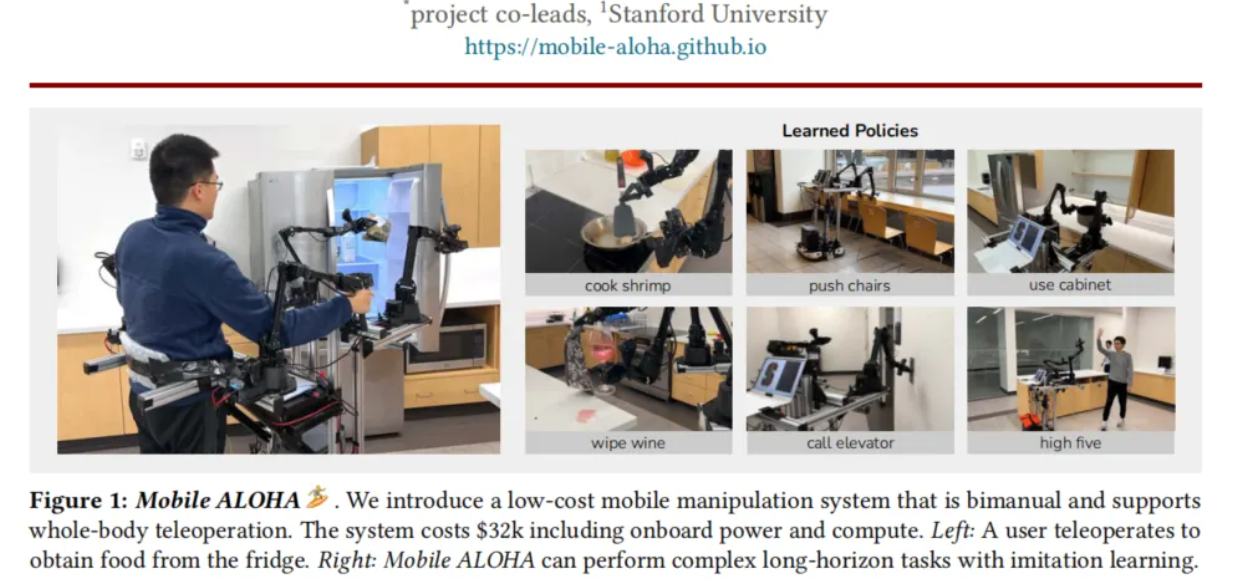

左图展示人通过遥操作控制机器人从冰箱取食物。右侧标题 `Learned Policies` 表示学习得到的策略，列出六个任务：

| 原图任务 | 含义 |
|---|---|
| `cook shrimp` | 烹饪虾 |
| `push chairs` | 推动椅子 |
| `use cabinet` | 操作柜子 |
| `wipe wine` | 擦拭洒出的酒液 |
| `call elevator` | 呼叫电梯 |
| `high five` | 击掌 |

图注把 Mobile ALOHA 描述为支持全身遥操作的双臂移动操作系统，并说明它可以通过模仿学习完成较长操作序列的任务。图注记录的系统成本为约 **3.2 万美元**，包含机载供电与计算设备，这是论文截图中的原始介绍。

课件这一页的备注是“看论文，看视频”，图中给出的项目入口为 [Mobile ALOHA](https://mobile-aloha.github.io)。本页展示的是研究案例，课件没有展开其模型结构、训练参数或复现实验步骤。


## 3. 行为克隆：学习情境与专家动作之间的对应关系

第 3 页介绍**行为克隆（Behavior Cloning，BC）**：通过监督学习，让机械臂学习人类操作的映射关系。

监督学习需要输入和相应的目标输出。在行为克隆中，可以把它们理解为“专家当时获得的环境信息”和“专家在此时采取的动作”。训练得到的策略在接收到相应信息后，预测应该执行什么动作。

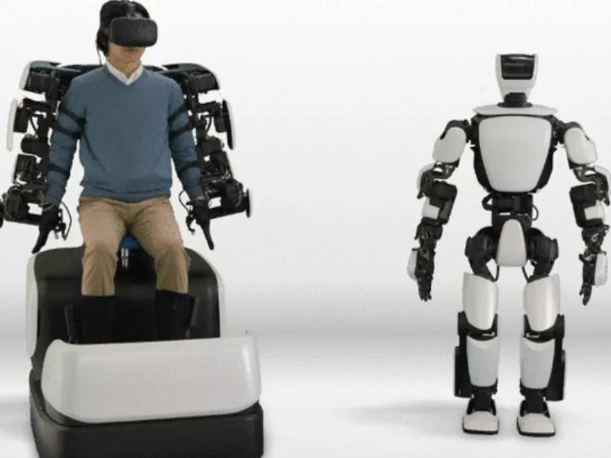

课件强调从“手动控制（教师端）”到“自动模仿（机械臂执行）”的过程，并以复杂抓取任务作为应用场景。

### 3.1 从示范到自动执行

**对课件流程的展开说明：**

1. 人通过教师端进行示范，控制机器人完成操作。
2. 记录示范过程中对应的观测与动作，形成训练样本。
3. 用监督学习训练策略，使模型输出接近示范动作。
4. 自动执行时，策略根据当前观测产生动作，由机器人执行。

这里的“专家”指提供示范的操作者。教师端在本课中是人的操作入口，不是模型蒸馏中的教师模型。

**补充辨析：**实时遥操作说明人能够控制机器人，本身还不能证明机器人已经学会。行为克隆还需要数据记录与训练过程。课件没有给出采集文件格式、输入字段或损失函数。

课件同时提出，模仿学习、行为克隆可以为后续强化学习提供初始策略。这个用途会在后面继续展开。


## 4. 自动驾驶中的行为克隆

课件第 4 页将同样的思路放到自动驾驶中：系统观察人类驾驶员在不同情境下的决策，学习如何根据路况选择驾驶动作。

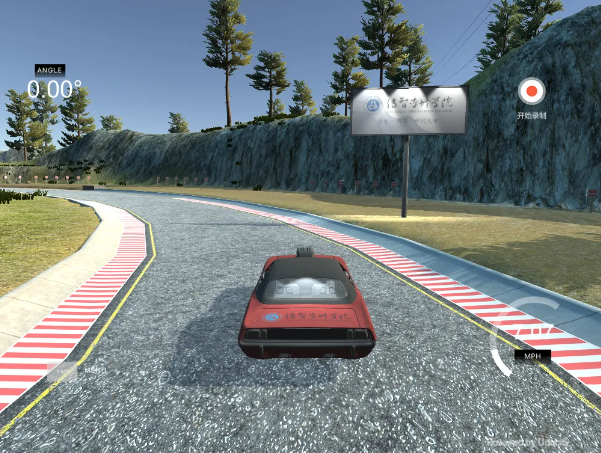

对应关系仍然是：驾驶员提供示范，系统从示范中学习策略，使用策略时依据当前路况作出动作选择。

**帮助理解的例子：**道路画面、车辆状态等可以作为输入，驾驶员的转向、加速或制动操作可以作为学习目标。这里用来解释“输入与动作”的对应关系，课件没有指定实际数据字段。

与机械臂抓取相比，任务和动作发生了变化，但行为克隆的学习依据相同，都是专家在具体情境下的选择。原图是仿真驾驶画面，课件没有给出可运行工程或测试成绩。


## 5. 从模仿学习过渡到强化学习

第 5 页提出两阶段思路：先模仿人类操作，让机械臂获得初始策略，再引入奖励，通过交互优化任务执行方式。

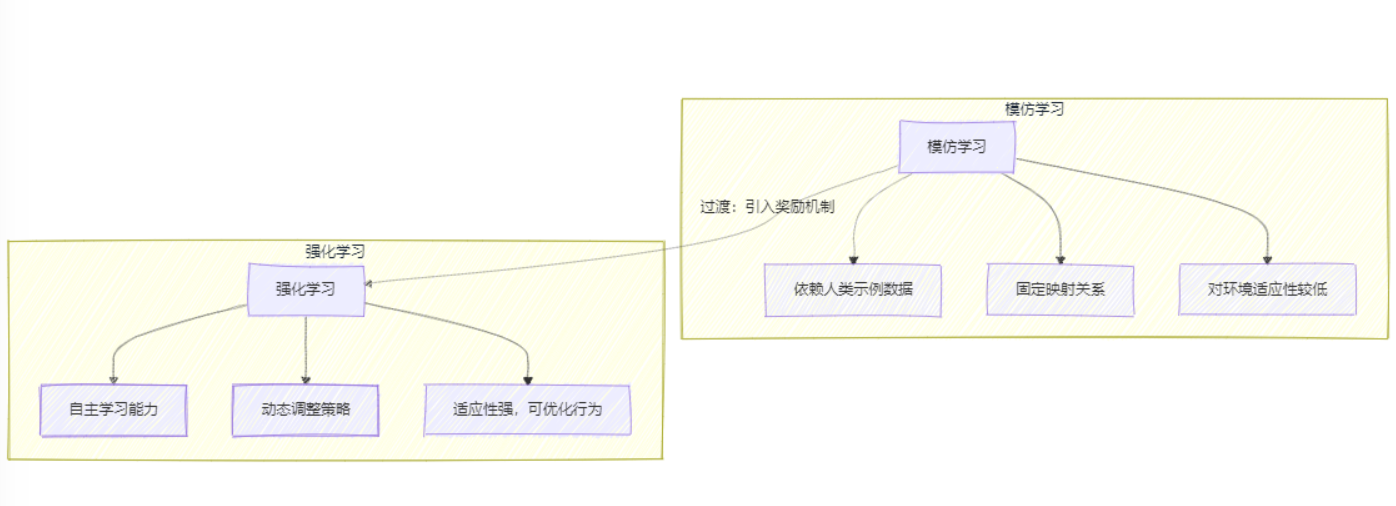

原图将模仿学习概括为“依赖人类示例数据”“固定映射关系”“对环境适应性较低”，将强化学习概括为“自主学习能力”“动态调整策略”“适应性强、可优化行为”。这些表述用于突出两阶段的学习依据。

| 阶段 | 学习依据 | 课件希望达到的效果 |
|---|---|---|
| 模仿学习 | 人类示范中的情境与动作 | 先学会任务的大致流程，形成初始策略 |
| 强化学习 | 与环境交互获得的奖励 | 继续调整策略，寻找更好的任务执行方式 |

“预训练”在这里指先完成一阶段学习，用它的结果初始化后续学习。行为克隆也可以独立用于执行任务，并非一定要接强化学习。

**原图辨析：**“固定映射”可以理解为训练完成、参数暂不更新的策略，模型仍会根据不同输入输出不同动作，也可能泛化到相近情境。引入奖励和后续训练为改进行为提供了途径，是否更适应环境仍取决于数据、奖励设计与训练条件。


## 6. 行为克隆与强化学习的比较

第 6 页从学习方式和应用场景进行对比。

| 学习方式 | 课件中的学习机制 | 课件列出的应用 |
|---|---|---|
| 行为克隆 BC | 基于监督学习，通过专家数据直接模仿行为 | 自动驾驶、工业机器人抓取 |
| 强化学习 RL | 基于试错过程，通过奖励信号优化策略 | 游戏 AI，例如 AlphaGo；机器人自主学习 |

### 6.1 课件中的三项对比

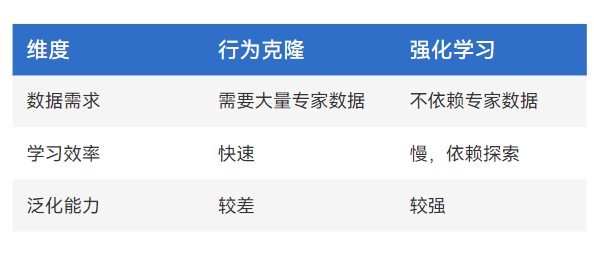

| 维度 | 行为克隆：课件原表 | 强化学习：课件原表 |
|---|---|---|
| 数据需求 | 需要大量专家数据 | 不依赖专家数据 |
| 学习效率 | 快速 | 慢，依赖探索 |
| 泛化能力 | 较差 | 较强 |

这张表表达的是入门对比，使用时需要结合条件理解：

- **数据：**BC 依赖示范的质量与覆盖范围，所需数量随任务变化。RL 的核心反馈是奖励，可以不使用专家示范，也可以结合示范训练。
- **效率：**已有合适示范时，BC 通常能减少从零探索的需求，但采集示范也有成本。RL 的交互量与训练难度取决于任务和算法。
- **泛化：**BC 在示范未覆盖的情境中容易出错，误差还可能把系统带到更陌生的状态。RL 也可能只适应训练环境，不能仅凭方法名称判断谁的泛化能力一定更强。

**案例补充：**早期 AlphaGo 同时使用过人类棋谱的监督学习与强化学习。课件将其列作 RL 应用，不能理解为该系统完全没有利用专家数据。


## 7. 行为克隆与离线强化学习的区别

第 7 页写道：“行为克隆可以理解为，离线强化学习（Offline RL）”，随后用“从一个固定的、离线的数据集中学习策略，而不能与环境进行新的交互”解释离线学习。

**概念修正：**这段话抓住了使用固定数据的特点，但把学习条件和学习目标混在了一起。需要分别看“数据如何获得”和“训练依据是什么”。

| 概念 | 学习依据与目标 | 与已有数据的关系 |
|---|---|---|
| 模仿学习（Imitation Learning） | 从专家示范中学习行为或策略 | 是一类方法，行为克隆是其中一种 |
| 行为克隆（BC） | 用监督学习，让预测动作接近专家动作 | 可在固定示范数据上训练，基本 BC 不需要任务奖励 |
| 离线强化学习（Offline RL） | 利用已有交互数据及奖励信息，优化累计回报 | 训练阶段不再通过新环境交互收集数据 |
| 在线强化学习（Online RL） | 根据奖励优化策略 | 学习过程中继续与环境交互、获得新数据 |

因此，**使用离线数据训练 BC，并不等于进行了离线强化学习**。BC 可以作为离线强化学习中的基线或组成部分，二者的训练目标仍有区别。

这里的“离线”描述训练的数据获取条件。它不表示机器人部署后不能执行动作，也不单纯指电脑有没有连接互联网。


## 8. LeRobot 预训练与强化学习微调的课程思路

课件最后用两个步骤描述如何结合模仿学习与强化学习，并提到 **LeRobot** 与 **Stable-Baselines3**。

### 8.1 先通过模仿学习获得初始策略

课件建议先使用 LeRobot 和相关数据集进行模仿学习训练。目标是让策略掌握任务的大致流程，为后续训练提供一个较好的起点，减少从零开始的盲目探索。

这里的产物是可用于初始化后续学习的策略。课件没有指定数据集名称、机器人型号、策略架构或训练配置。

### 8.2 再通过在线强化学习改进策略

第二步是把初始策略用于机器人，再利用强化学习算法进行**在线微调（Fine-tuning）**。课件以从 Stable-Baselines3 中选用算法为例，通过新的交互与奖励继续更新策略。

前一阶段学习专家怎样做，后一阶段则根据任务奖励继续优化。由于第二阶段会获得新的环境交互数据，它属于课件所描述的在线训练过程。

> **实现边界：**这是一条训练思路，并不意味着任意 LeRobot 策略都能直接加载进 Stable-Baselines3。实际衔接需要匹配观测与动作表示、策略网络和参数格式，还需要适配环境接口、定义奖励与任务结束条件。课件没有提供这些连接步骤或代码。

课件提到“少量真实交互”可以进一步优化策略，但没有给出交互次数或实验结果，应理解为希望降低交互成本，而不是训练量或效果保证。本篇据此保留两阶段方法，不补写未经课件提供的安装命令、训练脚本或实机成绩。
